<a href="https://colab.research.google.com/github/patrykost-a11y/ROZPOZNAWANIE_GEST-W_D-ONI/blob/main/Rozpoznawanie_gest%C3%B3w_g%C5%82oni.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

GPU: []
Found 2520 files belonging to 3 classes.
Found 372 files belonging to 3 classes.


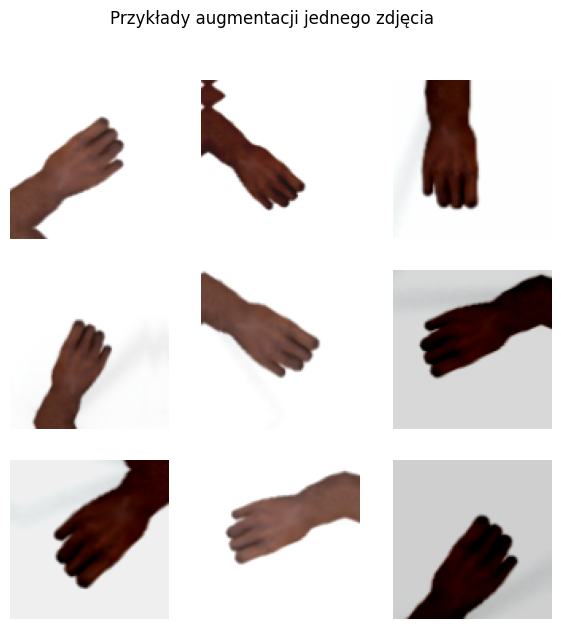

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentacja (Sequential)        │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     1,638,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,732,163 (6.61 MB)

 Trainable params: 1,732,163 (6.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 98s 2s/step - accuracy: 0.4044 - loss: 1.0684 - val_accuracy: 0.5296 - val_loss: 0.8886
Epoch 2/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.5885 - loss: 0.8615 - val_accuracy: 0.8011 - val_loss: 0.5345
Epoch 3/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 61s 2s/step - accuracy: 0.7437 - loss: 0.5934 - val_accuracy: 0.8602 - val_loss: 0.3767
Epoch 4/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 59s 1s/step - accuracy: 0.8024 - loss: 0.4854 - val_accuracy: 0.7581 - val_loss: 0.5769
Epoch 5/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 92s 2s/step - accuracy: 0.8762 - loss: 0.3564 - val_accuracy: 0.9355 - val_loss: 0.1740
Epoch 6/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 72s 2s/step - accuracy: 0.8956 - loss: 0.3038 - val_accuracy: 0.9409 - val_loss: 0.1789
Epoch 7/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 61s 2s/step - accuracy: 0.8976 - loss: 0.2853 - val_accuracy: 0.9651 - val_loss: 0.1101
Epoch 8/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - accuracy: 0.9278 - loss: 0.2059 - val_accuracy: 0.8629 - val_loss:

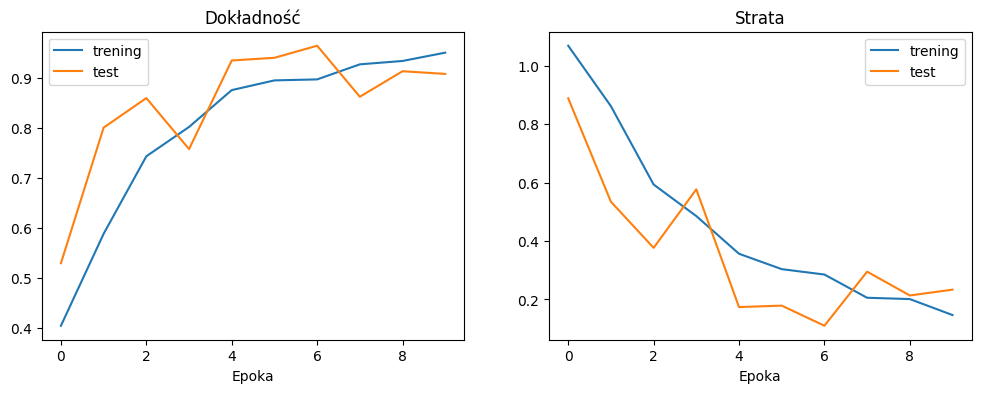

Dokładność na teście: 96.51 %
              precision    recall  f1-score   support

       paper       0.99      0.90      0.95       124
        rock       0.95      1.00      0.98       124
    scissors       0.95      0.99      0.97       124

    accuracy                           0.97       372
   macro avg       0.97      0.97      0.96       372
weighted avg       0.97      0.97      0.96       372



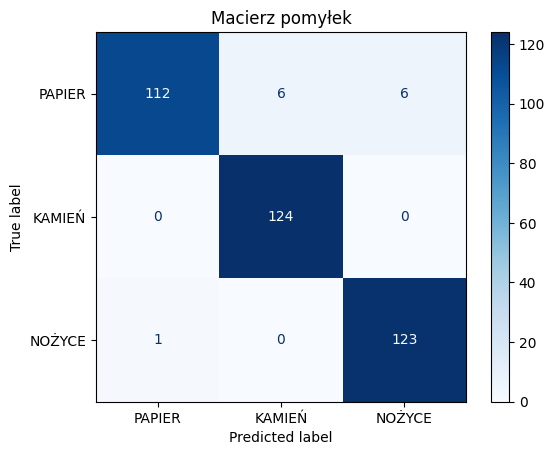

Model został zapisany.
Prześlij zdjęcie dłoni (najlepiej na jasnym, jednolitym tle).


In [ ]:
# PROJEKT: ROZPOZNAWANIE GESTÓW DŁONI kamień, papier, nożyce
import tensorflow as tf, numpy as np, matplotlib.pyplot as plt, zipfile, urllib.request
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from google.colab import files
from PIL import Image, ImageOps

print("GPU:", tf.config.list_physical_devices("GPU"))

url = "https://storage.googleapis.com/learning-datasets/"
for plik in ["rps.zip", "rps-test-set.zip"]:
    urllib.request.urlretrieve(url + plik, plik)
    zipfile.ZipFile(plik).extractall("dataset")

ROZMIAR = 100
BATCH = 64
klasy = ["paper", "rock", "scissors"]
nazwy = {"rock": "KAMIEŃ", "paper": "PAPIER", "scissors": "NOŻYCE"}

trening = tf.keras.utils.image_dataset_from_directory(
    "dataset/rps", image_size=(ROZMIAR, ROZMIAR), batch_size=BATCH,
    class_names=klasy, label_mode="categorical", seed=42)
test = tf.keras.utils.image_dataset_from_directory(
    "dataset/rps-test-set", image_size=(ROZMIAR, ROZMIAR), batch_size=BATCH,
    class_names=klasy, label_mode="categorical", shuffle=False)

trening = trening.cache().shuffle(1000).prefetch(tf.data.AUTOTUNE)
test = test.cache().prefetch(tf.data.AUTOTUNE)

augmentacja = models.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.3),
    layers.RandomBrightness(0.2),
], name="augmentacja")

obrazy, _ = next(iter(trening))
plt.figure(figsize=(7, 7))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(augmentacja(obrazy[:1], training=True)[0].numpy().astype("uint8"))
    plt.axis("off")
plt.suptitle("Przykłady augmentacji jednego zdjęcia")
plt.show()

model = models.Sequential([
    layers.Input(shape=(ROZMIAR, ROZMIAR, 3)),
    augmentacja,
    layers.Rescaling(1./255),
    layers.Conv2D(32, 3, activation="relu"),  layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),  layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(3, activation="softmax")
])
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

stop = tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3,
                                        restore_best_weights=True)
wyniki = model.fit(trening, validation_data=test, epochs=12, callbacks=[stop])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(wyniki.history["accuracy"], label="trening")
ax[0].plot(wyniki.history["val_accuracy"], label="test")
ax[0].set_title("Dokładność"); ax[0].set_xlabel("Epoka"); ax[0].legend()
ax[1].plot(wyniki.history["loss"], label="trening")
ax[1].plot(wyniki.history["val_loss"], label="test")
ax[1].set_title("Strata"); ax[1].set_xlabel("Epoka"); ax[1].legend()
plt.show()

strata, dokladnosc = model.evaluate(test, verbose=0)
print("Dokładność na teście:", round(dokladnosc * 100, 2), "%")

y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test])
y_pred = np.argmax(model.predict(test, verbose=0), axis=1)
print(classification_report(y_true, y_pred, target_names=klasy))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                       display_labels=[nazwy[k] for k in klasy]).plot(cmap="Blues")
plt.title("Macierz pomyłek"); plt.show()

model.save("model_gesty.keras")
print("Model został zapisany.")

def przygotuj(sciezka):
    obraz = Image.open(sciezka)
    obraz = ImageOps.exif_transpose(obraz).convert("RGB")
    obraz = ImageOps.fit(obraz, (ROZMIAR, ROZMIAR))
    obraz = ImageOps.autocontrast(obraz, cutoff=1)
    return obraz

print("Prześlij zdjęcie dłoni (najlepiej na jasnym, jednolitym tle).")
for nazwa in files.upload():
    obraz = przygotuj(nazwa)
    dane = np.expand_dims(np.array(obraz, dtype="float32"), 0)
    p = model.predict(dane, verbose=0)[0]
    gest = klasy[np.argmax(p)]
    plt.imshow(obraz); plt.axis("off")
    plt.title(f"{nazwy[gest]} ({p.max()*100:.1f}%)"); plt.show()
    print("Rozpoznany gest:", nazwy[gest], "| Pewność:", round(p.max() * 100, 2), "%")

print("Koniec programu!")